In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

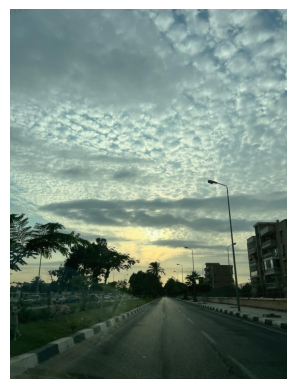

In [7]:
import cv2
import matplotlib.pyplot as plt

# Read image
img = cv2.imread('imggg.jpeg')

# Display image
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

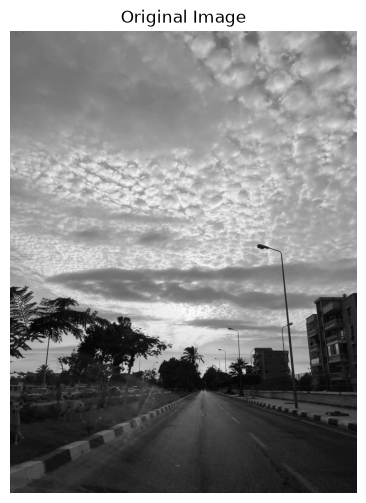

In [8]:
# Read image
img = cv2.imread('imggg.jpeg')

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Display original image
plt.figure(figsize=(6, 6))
plt.imshow(gray, cmap='gray')
plt.title('Original Image')
plt.axis('off')
plt.show()

In [9]:
# Calculate gradients using Sobel
gx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
gy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

# Calculate magnitude and direction
magnitude = np.hypot(gx, gy)
angle = np.rad2deg(np.arctan2(gy, gx))
angle = (angle + 180) % 180

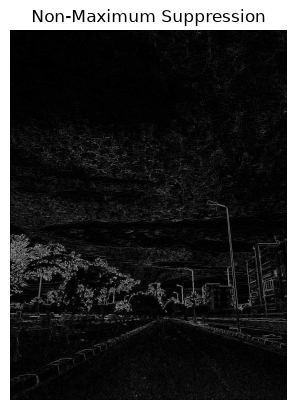

In [10]:
# Create output image
nms = np.zeros(gray.shape, dtype=np.uint8)

# Apply Non-Maximum Suppression
for i in range(1, gray.shape[0] - 1):
    for j in range(1, gray.shape[1] - 1):

        direction = angle[i, j]
        current = magnitude[i, j]

        if direction < 22.5 or direction >= 157.5:
            neighbors = [magnitude[i, j-1], magnitude[i, j+1]]

        elif direction < 67.5:
            neighbors = [magnitude[i-1, j+1], magnitude[i+1, j-1]]

        elif direction < 112.5:
            neighbors = [magnitude[i-1, j], magnitude[i+1, j]]

        else:
            neighbors = [magnitude[i-1, j-1], magnitude[i+1, j+1]]

        if current >= max(neighbors):
            nms[i, j] = min(255, int(current))

# Display result
plt.imshow(nms, cmap='gray')
plt.title('Non-Maximum Suppression')
plt.axis('off')
plt.show()

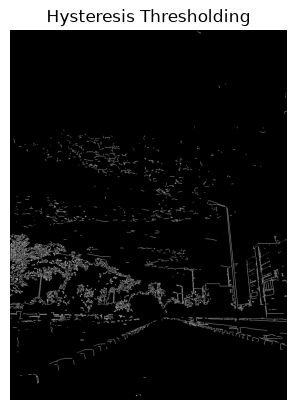

In [11]:
# Define thresholds
low = 50
high = 150

strong = 255
weak = 75

# Create output image
hysteresis = np.zeros(nms.shape, dtype=np.uint8)

# Classify pixels
hysteresis[nms >= high] = strong
hysteresis[(nms >= low) & (nms < high)] = weak

# Connect weak edges to strong edges
for i in range(1, nms.shape[0] - 1):
    for j in range(1, nms.shape[1] - 1):

        if hysteresis[i, j] == weak:

            if np.any(hysteresis[i-1:i+2, j-1:j+2] == strong):
                hysteresis[i, j] = strong
            else:
                hysteresis[i, j] = 0

# Display result
plt.imshow(hysteresis, cmap='gray')
plt.title('Hysteresis Thresholding')
plt.axis('off')
plt.show()

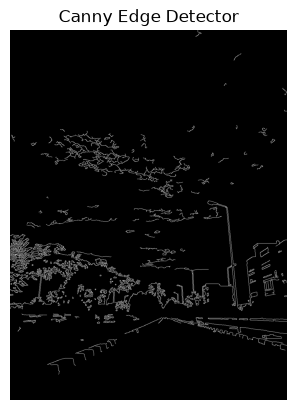

In [12]:
# Apply Gaussian Blur
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# Apply Canny
canny = cv2.Canny(blur, 50, 150)

# Display result
plt.imshow(canny, cmap='gray')
plt.title('Canny Edge Detector')
plt.axis('off')
plt.show()

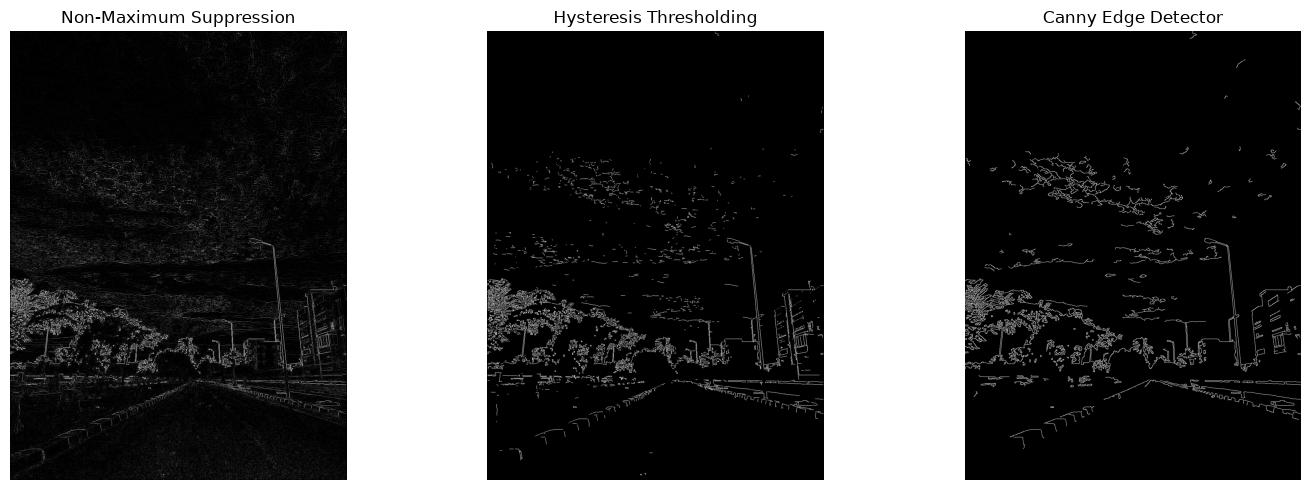

In [13]:
plt.figure(figsize=(15, 5))

# Non-Maximum Suppression
plt.subplot(1, 3, 1)
plt.imshow(nms, cmap='gray')
plt.title('Non-Maximum Suppression')
plt.axis('off')

# Hysteresis Thresholding
plt.subplot(1, 3, 2)
plt.imshow(hysteresis, cmap='gray')
plt.title('Hysteresis Thresholding')
plt.axis('off')

# Canny Edge Detector
plt.subplot(1, 3, 3)
plt.imshow(canny, cmap='gray')
plt.title('Canny Edge Detector')
plt.axis('off')

plt.tight_layout()
plt.show()

In [14]:
methods = ['NMS', 'Hysteresis', 'Canny']

results = [nms, hysteresis, canny]

for name, result in zip(methods, results):
    edge_pixels = np.sum(result == 255)
    print(f'{name}: {edge_pixels} edge pixels')

NMS: 12778 edge pixels
Hysteresis: 28594 edge pixels
Canny: 29257 edge pixels
